# SigLIP-2 + Metadata Fusion — Fakeddit Binary Fake News Detection (v2)
**2-Way Classification Only — 3-way and 6-way are cancelled**

## Model: SigLIP-2 (google/siglip-so400m-patch14-384)
- **Architecture**: Vision + Text encoders with cross-modal alignment
- **Task**: Binary classification (Real=0 vs Fake=1)
- **Dataset**: Fakeddit (5 000 balanced samples, 2-way label only)

## Metadata Branch (NEW):
- **Numerical features (13)**: engagement stats (num_comments, score, upvote_ratio), has_image flag, time-of-day signals, title statistics (length, capital ratio, punctuation density)
- **Domain embedding**: source domain → trainable Embedding(top-100 + OOV, 32)
- **Feature dropout**: 10 % of features randomly zeroed during training

## Architecture:
```
img_embed ──┐
            ├→ vision_proj (256-d)  ─┐
txt_embed ──┘                        │
                                     ├─→ concat [vis, txt, meta]  768-d
meta_num + domain_id → MetadataEncoder (256-d) ─┘
                                     ↓
                       LayerNorm → 512 → 256 → 2
```

## Configuration:
- 5-Fold Cross-Validation
- 80 % train / 10 % val / 10 % test per fold
- 10 epochs, early stopping patience=3
- Stochastic Weight Averaging (SWA, last 3 epochs)
- Anti-overfitting: dropout, weight decay, label smoothing, feature dropout

## Classification Scope:
❌ 6-way classification — **DISABLED**
❌ 3-way classification — **DISABLED**
✅ 2-way classification — **ONLY mode active**


In [2]:
# ── Cell 1: Install Dependencies ─────────────────────────────────────────────
import sys
import subprocess

print("Installing SigLIP and dependencies...\n")

packages = [
    "transformers>=4.40.0",  # SigLIP requires newer transformers
    "pillow",
    "tabulate",
    "scikit-learn",
]

for i, pkg in enumerate(packages, 1):
    print(f"[{i}/{len(packages)}] Installing {pkg}...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

print("\n✓ All packages installed!\n")

# Verify
try:
    from transformers import AutoProcessor, AutoModel
    import torch
    print("✓ Transformers imported successfully")
    print(f"  Version: {__import__('transformers').__version__}")
    print(f"  PyTorch: {torch.__version__}")
except ImportError as e:
    print("✗ Import failed!")
    raise e

Installing SigLIP and dependencies...

[1/4] Installing transformers>=4.40.0...
[2/4] Installing pillow...
[3/4] Installing tabulate...
[4/4] Installing scikit-learn...

✓ All packages installed!

✓ Transformers imported successfully
  Version: 5.0.0
  PyTorch: 2.10.0+cu128


In [3]:
# ── Cell 2: Imports & Configuration ──────────────────────────────────────────
import os, gc, json, random, warnings, copy, math, datetime
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.optim.swa_utils import AveragedModel
from PIL import Image

from transformers import AutoProcessor, AutoModel
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix,
)
from tabulate import tabulate
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# ════════════════════════ CONFIGURATION ══════════════════════════════════════
SEED          = 42
NUM_SAMPLES   = 5000
NUM_FOLDS     = 5
EPOCHS        = 10
BATCH_SIZE    = 8            # SO400M + 384 px; keep small to fit T4 (15 GB)
LEARNING_RATE = 2e-5
WEIGHT_DECAY  = 1e-2
DROPOUT_RATE  = 0.30
PATIENCE      = 3
NUM_CLASSES   = 2            # 2-WAY ONLY  (3-way and 6-way are cancelled)
DEVICE        = "cuda" if torch.cuda.is_available() else "cpu"

SIGLIP_MODEL  = "google/siglip-so400m-patch14-384"
OUTPUT_DIR    = "/kaggle/working"

# ── Metadata branch ───────────────────────────────────────────────────────────
META_TOP_K_DOMAINS    = 100   # top-K source domains to embed (rest → OOV=0)
META_DOMAIN_EMBED_DIM = 32    # embedding size for domain token
META_FEAT_DROPOUT     = 0.10  # fraction of features zeroed in training
META_ENCODER_DIM      = 256   # output dim of MetadataEncoder

# ── SWA ───────────────────────────────────────────────────────────────────────
USE_SWA      = True
SWA_START_EP = max(EPOCHS - 3, 1)   # start averaging at this epoch

# Seeds
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

USE_AMP = DEVICE == "cuda"

print(f"Device      : {DEVICE}")
print(f"GPU         : {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'None'}")
print(f"Model       : SigLIP-2 SO400M")
print(f"Task        : 2-way ONLY  (3-way & 6-way CANCELLED)")
print(f"Metadata    : domain embed + 13 numerical features")
print(f"SWA         : {'enabled (last 3 epochs)' if USE_SWA else 'disabled'}")
print(f"Config      : {EPOCHS} epochs | {NUM_FOLDS} folds | batch {BATCH_SIZE}")
print("=" * 70)


Device      : cuda
GPU         : Tesla T4
Model       : SigLIP-2 SO400M
Task        : 2-way ONLY  (3-way & 6-way CANCELLED)
Metadata    : domain embed + 13 numerical features
SWA         : enabled (last 3 epochs)
Config      : 10 epochs | 5 folds | batch 8


In [4]:
# ── Cell 3: Fakeddit Dataset Loader ──────────────────────────────────────────

def load_fakeddit(n_samples=NUM_SAMPLES):
    """Load Fakeddit dataset (2-way ONLY) with metadata columns."""
    print("Scanning for Fakeddit dataset...\n")
    for tsv in Path("/kaggle/input").rglob("*.tsv"):
        print(f"Found TSV: {tsv.name}")
        return load_from_tsv(tsv, n_samples)
    for csv in Path("/kaggle/input").rglob("*.csv"):
        print(f"Found CSV: {csv.name}")
        return load_from_tsv(csv, n_samples)
    raise FileNotFoundError(
        "No Fakeddit dataset found!\n"
        "Upload a TSV/CSV with '2_way_label', 'clean_title'/'title', 'id' columns."
    )


def load_from_tsv(file_path, n_samples):
    sep = "\t" if file_path.suffix == ".tsv" else ","
    df  = pd.read_csv(file_path, sep=sep, low_memory=False)
    df.columns = df.columns.str.strip()
    print(f"\nRaw columns: {list(df.columns[:12])}...")

    text_col = next((c for c in ["clean_title", "title", "text"] if c in df.columns), None)
    id_col   = "id" if "id" in df.columns else df.columns[0]

    # ── 2-way ONLY — 3-way & 6-way columns ignored ────────────────────────────
    if "2_way_label" not in df.columns:
        raise ValueError(
            f"Missing '2_way_label' column. Found: {list(df.columns)}\n"
            "Note: 3-way and 6-way classification are cancelled."
        )
    if not text_col:
        raise ValueError(f"Missing text column. Found: {list(df.columns[:10])}")

    # ── Metadata columns (loaded if present) ──────────────────────────────────
    META_COLS = ["domain", "num_comments", "score", "hasImage",
                 "created_utc", "upvote_ratio", "subreddit", "image_url"]
    avail_meta = [c for c in META_COLS if c in df.columns]
    keep = [id_col, text_col, "2_way_label"] + avail_meta
    df   = df[keep].dropna(subset=["2_way_label"])
    df   = df.rename(columns={id_col: "id", text_col: "text", "2_way_label": "label"})
    df["label"] = df["label"].astype(int)

    # ── Keep ONLY 2-way labels ────────────────────────────────────────────────
    df = df[df["label"].isin([0, 1])]

    # Clean text
    df["text"] = (
        df["text"].astype(str).str.strip()
        .apply(lambda x: x[:300] if len(x) > 300 else x)
        .replace("", "[No text]")
    )

    # Numeric coercion for metadata
    for col in ["num_comments", "score", "created_utc", "upvote_ratio"]:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0)
    if "hasImage" in df.columns:
        df["hasImage"] = pd.to_numeric(df["hasImage"], errors="coerce").fillna(0).astype(float)

    # Find images
    img_dir = file_path.parent / "public_image_set"
    if img_dir.exists():
        df["image_path"] = df["id"].apply(lambda x: find_image(x, img_dir))
        df = df[df["image_path"].notna()]
    else:
        df["image_path"] = None
        for cand in file_path.parent.rglob("*image*"):
            if cand.is_dir():
                df["image_path"] = df["id"].apply(lambda x: find_image(x, cand))
                break

    print(f"Metadata columns loaded: {avail_meta}")
    return balance_df(df, n_samples)


def find_image(img_id, img_dir):
    for ext in [".jpg", ".jpeg", ".png", ".gif", ".webp"]:
        p = img_dir / f"{img_id}{ext}"
        if p.exists():
            return str(p)
    return None


def balance_df(df, n_samples):
    if len(df) == 0:
        raise ValueError("No valid 2-way samples found!")
    half   = n_samples // 2
    fake   = df[df["label"] == 1].sample(min(half, (df["label"] == 1).sum()), random_state=SEED)
    real   = df[df["label"] == 0].sample(min(half, (df["label"] == 0).sum()), random_state=SEED)
    actual = min(len(fake), len(real))
    out    = pd.concat([fake.iloc[:actual], real.iloc[:actual]])
    out    = out.sample(frac=1, random_state=SEED).reset_index(drop=True)
    print(f"\nLoaded {len(out)} samples  (Real={actual}, Fake={actual})")
    if "image_path" in out.columns:
        print(f"  Images found : {out['image_path'].notna().sum()}")
    meta_avail = [c for c in ["domain", "num_comments", "score",
                               "hasImage", "created_utc"] if c in out.columns]
    print(f"  Metadata cols: {meta_avail}")
    print("\nSample rows:")
    for i in range(min(3, len(out))):
        row = out.iloc[i]
        print(f"  [{'FAKE' if row['label']==1 else 'REAL'}] {str(row['text'])[:60]}...")
    return out


print("Fakeddit loader ready")


Fakeddit loader ready


In [5]:
# ── Cell 4: MetadataExtractor + SigLIPDataset ────────────────────────────────

class MetadataExtractor:
    """
    Extracts and z-score-normalizes structured metadata from Fakeddit rows.

    Numerical features  (N_FEATURES = 13):
      0  log_num_comments   log(1 + num_comments)
      1  log_abs_score      log(1 + |score|)
      2  score_sign         +1 / -1
      3  has_image          0 / 1
      4  upvote_ratio       clipped to [0, 1]
      5  log_title_chars    log(1 + len(title))
      6  log_word_count     log(1 + n_words)
      7  capital_ratio      UPPER / max(1, alpha)
      8  exclaim_density    count('!') / max(1, n_words)
      9  question_density   count('?') / max(1, n_words)
     10  time_sin           sin(2π × hour / 24)
     11  time_cos           cos(2π × hour / 24)
     12  high_upvote_flag   1.0 if upvote_ratio > 0.75

    Domain feature:
      source domain → integer ID in domain_vocab; 0 = OOV
    """

    N_FEATURES = 13

    def __init__(self, top_k_domains=META_TOP_K_DOMAINS):
        self.top_k_domains = top_k_domains
        self.domain_vocab: dict = {}
        self.feat_mean = np.zeros(self.N_FEATURES, dtype=np.float32)
        self.feat_std  = np.ones(self.N_FEATURES,  dtype=np.float32)
        self._fitted   = False

    @property
    def n_domains(self):
        return len(self.domain_vocab) + 1   # +1 for OOV = 0

    def _raw_features(self, row_dict: dict) -> list:
        text         = str(row_dict.get("text", "") or "")
        num_comments = float(row_dict.get("num_comments", 0) or 0)
        score        = float(row_dict.get("score", 0) or 0)
        has_image    = float(row_dict.get("hasImage", 0) or 0)
        created_utc  = float(row_dict.get("created_utc", 0) or 0)
        upvote_ratio = float(row_dict.get("upvote_ratio", 0.5) or 0.5)
        upvote_ratio = max(0.0, min(1.0, upvote_ratio))
        try:
            dt   = datetime.datetime.utcfromtimestamp(created_utc)
            hour = dt.hour
        except Exception:
            hour = 0
        words   = text.split()
        n_words = max(1, len(words))
        n_chars = max(1, len(text))
        alpha   = max(1, sum(c.isalpha() for c in text))
        return [
            math.log1p(num_comments),
            math.log1p(abs(score)),
            1.0 if score >= 0 else -1.0,
            has_image,
            upvote_ratio,
            math.log1p(n_chars),
            math.log1p(n_words),
            sum(c.isupper() for c in text) / alpha,
            text.count("!") / n_words,
            text.count("?") / n_words,
            math.sin(2 * math.pi * hour / 24),
            math.cos(2 * math.pi * hour / 24),
            float(upvote_ratio > 0.75),
        ]

    def fit(self, df_train: "pd.DataFrame") -> "MetadataExtractor":
        """Fit domain vocabulary and feature statistics on training split."""
        domain_counts: Counter = Counter()
        all_feats = []
        for _, row in df_train.iterrows():
            d = str(row.get("domain", "") or "").lower().strip()
            if d:
                domain_counts[d] += 1
            all_feats.append(self._raw_features(row.to_dict()))
        top_d = [d for d, _ in domain_counts.most_common(self.top_k_domains - 1) if d]
        self.domain_vocab = {d: i + 1 for i, d in enumerate(top_d)}
        arr = np.array(all_feats, dtype=np.float32)
        self.feat_mean = arr.mean(axis=0)
        self.feat_std  = arr.std(axis=0)
        self.feat_std[self.feat_std < 1e-6] = 1.0
        self._fitted = True
        print(f"  MetadataExtractor: {self.n_domains} domains, "
              f"{self.N_FEATURES} numerical features")
        return self

    def extract(self, row_dict: dict, training: bool = False):
        """
        Returns (feat: np.float32[N_FEATURES], domain_id: int).
        training=True applies feature dropout for regularization.
        """
        raw  = np.array(self._raw_features(row_dict), dtype=np.float32)
        feat = (raw - self.feat_mean) / self.feat_std
        if training and META_FEAT_DROPOUT > 0:
            mask = (np.random.rand(self.N_FEATURES) > META_FEAT_DROPOUT).astype(np.float32)
            feat = feat * mask
        domain    = str(row_dict.get("domain", "") or "").lower().strip()
        domain_id = self.domain_vocab.get(domain, 0)
        return feat, domain_id


class SigLIPDataset(Dataset):
    """
    Dataset for SigLIP + metadata.

    Batch keys returned:
      pixel_values   (3, H, W)
      input_ids      (max_length,)
      attention_mask (max_length,)   -- if tokenizer produces it
      meta_num       (N_FEATURES,)   float32
      meta_domain    ()              int64
      labels         ()              int64
    """

    def __init__(self, df, processor, meta_extractor=None,
                 augment=False, training=False):
        self.df             = df.reset_index(drop=True)
        self.processor      = processor
        self.meta_extractor = meta_extractor
        self.training       = training
        self.placeholder    = Image.new("RGB", (384, 384), (127, 127, 127))

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        text  = str(row["text"])
        label = int(row["label"])

        img_path = row.get("image_path")
        try:
            img = Image.open(img_path).convert("RGB") if img_path else self.placeholder
        except Exception:
            img = self.placeholder

        inputs = self.processor(
            text=text, images=img,
            return_tensors="pt", padding="max_length",
            truncation=True, max_length=64,
        )
        inputs = {k: v.squeeze(0) for k, v in inputs.items()}
        inputs["labels"] = torch.tensor(label, dtype=torch.long)

        if self.meta_extractor is not None:
            feat, dom_id = self.meta_extractor.extract(
                row.to_dict(), training=self.training)
            inputs["meta_num"]    = torch.from_numpy(feat)
            inputs["meta_domain"] = torch.tensor(dom_id, dtype=torch.long)

        return inputs


def collate_fn(batch):
    """Collate any keys the dataset returns (handles variable key sets)."""
    labels = torch.stack([b["labels"] for b in batch])
    result = {"labels": labels}
    for key in batch[0].keys():
        if key != "labels":
            result[key] = torch.stack([b[key] for b in batch])
    return result


print("MetadataExtractor + SigLIPDataset defined")


MetadataExtractor + SigLIPDataset defined


In [6]:
# ── Cell 5: MetadataEncoder + SigLIPClassifier ───────────────────────────────

class MetadataEncoder(nn.Module):
    """
    Encodes (meta_num, meta_domain) → META_ENCODER_DIM embedding.
    meta_num    : float32 (B, N_FEATURES)  z-score normalised
    meta_domain : int64   (B,)             vocabulary ID (0 = OOV)
    """

    def __init__(self, n_num, n_domains,
                 out_dim=META_ENCODER_DIM,
                 domain_embed_dim=META_DOMAIN_EMBED_DIM,
                 dropout=0.30):
        super().__init__()
        self.embed = nn.Embedding(n_domains, domain_embed_dim, padding_idx=0)
        in_dim     = n_num + domain_embed_dim
        self.net   = nn.Sequential(
            nn.Linear(in_dim, 128),
            nn.LayerNorm(128),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(128, out_dim),
            nn.LayerNorm(out_dim),
            nn.GELU(),
            nn.Dropout(dropout * 0.5),
        )
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, meta_num, meta_domain):
        d = self.embed(meta_domain)
        x = torch.cat([meta_num, d], dim=-1)
        return self.net(x)


class SigLIPClassifier(nn.Module):
    """
    3-Branch fake-news detector:
      1. Vision branch  — SigLIP-2 image encoder  → proj_dim
      2. Text  branch   — SigLIP-2 text encoder   → proj_dim
      3. Meta  branch   — MetadataEncoder          → META_ENCODER_DIM

    Fusion: concat [vis_proj, txt_proj, meta_embed]  (768-d)
            → LayerNorm → 512 → 256 → num_classes

    Only last 2 vision encoder blocks are unfrozen; text stays frozen.
    """

    PROJ_DIM = 256   # shared projection dim for vision & text towers

    def __init__(self, siglip_model, meta_extractor,
                 num_classes=NUM_CLASSES, dropout=DROPOUT_RATE):
        super().__init__()
        self.siglip     = siglip_model
        self.vision_dim = siglip_model.config.vision_config.hidden_size
        self.text_dim   = siglip_model.config.text_config.hidden_size

        # ── Freeze entire backbone ────────────────────────────────────────────
        for p in self.siglip.parameters():
            p.requires_grad = False

        # Unfreeze last 2 vision encoder blocks
        if hasattr(self.siglip.vision_model, "encoder"):
            for layer in self.siglip.vision_model.encoder.layers[-2:]:
                for p in layer.parameters():
                    p.requires_grad = True

        # ── Metadata encoder ──────────────────────────────────────────────────
        self.meta_encoder = MetadataEncoder(
            n_num            = MetadataExtractor.N_FEATURES,
            n_domains        = meta_extractor.n_domains,
            out_dim          = META_ENCODER_DIM,
            domain_embed_dim = META_DOMAIN_EMBED_DIM,
            dropout          = 0.30,
        )

        # ── Vision / text projections → PROJ_DIM ─────────────────────────────
        D = self.PROJ_DIM
        self.vision_proj = nn.Sequential(
            nn.Linear(self.vision_dim, D), nn.LayerNorm(D), nn.GELU(), nn.Dropout(0.10))
        self.text_proj = nn.Sequential(
            nn.Linear(self.text_dim,   D), nn.LayerNorm(D), nn.GELU(), nn.Dropout(0.10))

        # ── Classifier head ───────────────────────────────────────────────────
        # [vis_proj, txt_proj, meta] = 256 + 256 + 256 = 768
        fused_dim = D + D + META_ENCODER_DIM
        self.classifier = nn.Sequential(
            nn.LayerNorm(fused_dim),
            nn.Dropout(dropout),
            nn.Linear(fused_dim, 512),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(512, 256),
            nn.GELU(),
            nn.Dropout(dropout * 0.5),
            nn.Linear(256, num_classes),
        )

        # Xavier init on all new linear layers
        for m in (list(self.vision_proj.modules())
                  + list(self.text_proj.modules())
                  + list(self.classifier.modules())):
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

        trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
        total     = sum(p.numel() for p in self.parameters())
        print(f"  SigLIPClassifier: {trainable/1e6:.1f}M / {total/1e6:.1f}M params trainable")
        print(f"  Fusion dim: {fused_dim}  (vis {D} + txt {D} + meta {META_ENCODER_DIM})")

    def forward(self, pixel_values, input_ids,
                attention_mask=None,
                meta_num=None, meta_domain=None,
                **unused):
        out = self.siglip(
            pixel_values=pixel_values,
            input_ids=input_ids,
            attention_mask=attention_mask,
            return_dict=True,
        )
        vis = out.image_embeds / out.image_embeds.norm(dim=-1, keepdim=True)
        txt = out.text_embeds  / out.text_embeds.norm(dim=-1, keepdim=True)

        p_vis = self.vision_proj(vis)
        p_txt = self.text_proj(txt)

        if meta_num is not None and meta_domain is not None:
            p_meta = self.meta_encoder(meta_num, meta_domain)
        else:
            p_meta = torch.zeros(p_vis.size(0), META_ENCODER_DIM, device=p_vis.device)

        fused = torch.cat([p_vis, p_txt, p_meta], dim=-1)
        return self.classifier(fused)


print("MetadataEncoder + SigLIPClassifier defined")


MetadataEncoder + SigLIPClassifier defined


In [7]:
# ── Cell 6: Training Helpers ──────────────────────────────────────────────────

class EarlyStopping:
    """Tracks val loss; saves best model state and corresponding train accuracy."""

    def __init__(self, patience=PATIENCE, delta=1e-4):
        self.patience       = patience
        self.delta          = delta
        self.best_score     = None
        self.counter        = 0
        self.best_state     = None
        self.best_train_acc = 0.0
        self.best_val_acc   = 0.0
        self.stop           = False

    def step(self, val_loss, val_acc, train_acc, model):
        score = -val_loss
        if self.best_score is None or score > self.best_score + self.delta:
            self.best_score     = score
            self.best_train_acc = train_acc
            self.best_val_acc   = val_acc
            self.best_state     = {k: v.cpu().clone()
                                   for k, v in model.state_dict().items()}
            self.counter        = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.stop = True

    def restore_best(self, model):
        if self.best_state:
            model.load_state_dict({k: v.to(DEVICE)
                                   for k, v in self.best_state.items()})


def train_epoch(model, loader, optimizer, criterion, scheduler, scaler):
    model.train()
    total_loss = correct = n = 0
    num_batches = len(loader)

    for step, batch in enumerate(loader, 1):
        labels = batch.pop("labels").to(DEVICE)
        batch  = {k: v.to(DEVICE) for k, v in batch.items()}

        optimizer.zero_grad()
        with torch.cuda.amp.autocast(enabled=USE_AMP):
            logits = model(**batch)
            loss   = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * labels.size(0)
        correct    += (logits.argmax(1) == labels).sum().item()
        n          += labels.size(0)

        if step % 25 == 0 or step == num_batches:
            print(f"    step {step:3d}/{num_batches} | "
                  f"loss={total_loss/n:.4f} | acc={correct/n:.4f}", flush=True)

    scheduler.step()
    return total_loss / n, correct / n


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    all_preds, all_labels = [], []

    for batch in loader:
        labels = batch.pop("labels").to(DEVICE)
        batch  = {k: v.to(DEVICE) for k, v in batch.items()}

        with torch.cuda.amp.autocast(enabled=USE_AMP):
            logits = model(**batch)
            loss   = criterion(logits, labels)

        total_loss += loss.item() * labels.size(0)
        all_preds.extend(logits.argmax(1).cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    n      = len(all_labels)
    y_true = np.array(all_labels)
    y_pred = np.array(all_preds)
    metrics = dict(
        loss      = total_loss / n,
        accuracy  = accuracy_score(y_true, y_pred),
        f1        = f1_score(y_true, y_pred, average="macro", zero_division=0),
        precision = precision_score(y_true, y_pred, average="macro", zero_division=0),
        recall    = recall_score(y_true, y_pred, average="macro", zero_division=0),
    )
    return metrics, y_pred, y_true


print("Training helpers ready")


Training helpers ready


In [8]:
# ── Cell 7: K-Fold Training Loop ──────────────────────────────────────────────

def run_kfold(df):
    skf     = StratifiedKFold(n_splits=NUM_FOLDS, shuffle=True, random_state=SEED)
    labels  = df["label"].values
    indices = np.arange(len(df))

    fold_results = []
    all_history  = []
    all_cms      = []

    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.synchronize()
        torch.cuda.empty_cache()
        free, total = torch.cuda.mem_get_info()
        print(f"GPU before start: {free/1e9:.1f} GB free / {total/1e9:.1f} GB total")

    print("Loading SigLIP processor and model...")
    processor   = AutoProcessor.from_pretrained(SIGLIP_MODEL)
    siglip_base = AutoModel.from_pretrained(SIGLIP_MODEL)  # float32, CPU
    siglip_base = siglip_base.cpu()
    siglip_init = {k: v.cpu().clone() for k, v in siglip_base.state_dict().items()}
    print("SigLIP loaded (float32, CPU)\n")

    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

    for fold, (train_val_idx, test_idx) in enumerate(skf.split(indices, labels), 1):
        print(f"\n{'='*70}")
        print(f"  FOLD {fold} / {NUM_FOLDS}")
        print(f"{'='*70}")

        # ── 80 / 10 / 10 split ───────────────────────────────────────────────
        np.random.shuffle(train_val_idx)
        mid        = len(test_idx) // 2
        val_idx    = test_idx[:mid]
        test_idx_f = test_idx[mid:]
        train_idx  = train_val_idx
        print(f"  Train: {len(train_idx)} | Val: {len(val_idx)} | Test: {len(test_idx_f)}")

        # ── Fit MetadataExtractor on this fold's training split ───────────────
        print("  Fitting MetadataExtractor...")
        meta_ext = MetadataExtractor(top_k_domains=META_TOP_K_DOMAINS)
        meta_ext.fit(df.iloc[train_idx])

        # ── Datasets & loaders ────────────────────────────────────────────────
        train_ds = SigLIPDataset(df.iloc[train_idx], processor,
                                 meta_extractor=meta_ext, training=True)
        val_ds   = SigLIPDataset(df.iloc[val_idx],   processor,
                                 meta_extractor=meta_ext, training=False)
        test_ds  = SigLIPDataset(df.iloc[test_idx_f],processor,
                                 meta_extractor=meta_ext, training=False)

        nw = 0   # 0 avoids Kaggle multiprocessing issues
        train_loader = DataLoader(train_ds, BATCH_SIZE, True,  collate_fn=collate_fn,
                                  num_workers=nw, pin_memory=(DEVICE == "cuda"))
        val_loader   = DataLoader(val_ds,   BATCH_SIZE, False, collate_fn=collate_fn,
                                  num_workers=nw, pin_memory=(DEVICE == "cuda"))
        test_loader  = DataLoader(test_ds,  BATCH_SIZE, False, collate_fn=collate_fn,
                                  num_workers=nw, pin_memory=(DEVICE == "cuda"))

        # ── Reset base weights & build model ──────────────────────────────────
        print("  Initializing model...")
        siglip_base.load_state_dict(siglip_init, strict=True)
        siglip_base.to(DEVICE)
        if DEVICE == "cuda":
            free, total = torch.cuda.mem_get_info()
            print(f"  GPU after model load: {free/1e9:.1f}/{total/1e9:.1f} GB")

        model     = SigLIPClassifier(siglip_base, meta_ext).to(DEVICE)
        criterion = nn.CrossEntropyLoss(label_smoothing=0.10)
        optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
        scheduler = CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
        es        = EarlyStopping(PATIENCE)

        # SWA wrapper
        swa_model = AveragedModel(model) if USE_SWA else None

        history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

        # ── Training loop ─────────────────────────────────────────────────────
        for epoch in range(1, EPOCHS + 1):
            print(f"\n  -- Epoch {epoch}/{EPOCHS} --")
            tr_loss, tr_acc = train_epoch(
                model, train_loader, optimizer, criterion, scheduler, scaler)
            val_m, _, _ = evaluate(model, val_loader, criterion)

            history["train_loss"].append(tr_loss)
            history["val_loss"].append(val_m["loss"])
            history["train_acc"].append(tr_acc)
            history["val_acc"].append(val_m["accuracy"])

            # SWA weight averaging
            if USE_SWA and swa_model is not None and epoch >= SWA_START_EP:
                swa_model.update_parameters(model)

            es.step(val_m["loss"], val_m["accuracy"], tr_acc, model)
            marker = "  <- best" if es.counter == 0 else ""
            print(f"  E{epoch:2d}/{EPOCHS} | TrL={tr_loss:.4f} TrA={tr_acc:.4f} | "
                  f"VaL={val_m['loss']:.4f} VaA={val_m['accuracy']:.4f}{marker}")

            if es.stop:
                print(f"  Early stop at epoch {epoch}")
                break

        # ── Restore best checkpoint ───────────────────────────────────────────
        es.restore_best(model)
        test_m, preds, true = evaluate(model, test_loader, criterion)

        # ── Optionally evaluate SWA model and use if better ──────────────────
        if USE_SWA and swa_model is not None:
            swa_model.eval()
            test_m_swa, preds_swa, _ = evaluate(swa_model, test_loader, criterion)
            if test_m_swa["accuracy"] > test_m["accuracy"]:
                test_m = test_m_swa
                preds  = preds_swa
                print(f"  SWA improved test acc: {test_m['accuracy']:.4f}")

        cm = confusion_matrix(true, preds)
        all_cms.append(cm)

        ovf_gap = es.best_train_acc - test_m["accuracy"]
        print(f"\n  -- Fold {fold} Test Results --")
        print(f"  Train Acc (best ep): {es.best_train_acc:.4f}")
        print(f"  Accuracy : {test_m['accuracy']:.4f}")
        print(f"  F1 Macro : {test_m['f1']:.4f}")
        print(f"  Precision: {test_m['precision']:.4f}")
        print(f"  Recall   : {test_m['recall']:.4f}")
        print(f"  Ovf Gap  : {ovf_gap:+.4f}\n")
        print(classification_report(true, preds, target_names=["Real", "Fake"]))

        fold_results.append({
            "Fold":        fold,
            "Train_Acc":   round(es.best_train_acc, 4),
            "Val_Acc":     round(es.best_val_acc,   4),
            "Accuracy":    round(test_m["accuracy"], 4),
            "F1_Macro":    round(test_m["f1"],       4),
            "Precision":   round(test_m["precision"],4),
            "Recall":      round(test_m["recall"],   4),
            "Overfit_Gap": round(ovf_gap,            4),
        })
        all_history.append(history)

        # ── Free GPU memory ───────────────────────────────────────────────────
        siglip_base.to("cpu")
        del model, optimizer, scheduler, es, swa_model
        gc.collect()
        if DEVICE == "cuda":
            torch.cuda.synchronize()
            torch.cuda.empty_cache()
            free, total = torch.cuda.mem_get_info()
            print(f"  GPU after cleanup: {free/1e9:.1f}/{total/1e9:.1f} GB\n")

    return fold_results, all_history, all_cms


print("K-fold runner ready")


K-fold runner ready


In [9]:
# ── Cell 8: Results & Visualization ───────────────────────────────────────────

def print_results_table(fold_results):
    """Print a rich results table with overfit gap and target status."""
    W = 80
    print("\n" + "=" * W)
    print("  SigLIP-2 + Metadata Fusion  |  Fakeddit  |  2-Way  |  Macro Average")
    print("  Target: >= 90 % Accuracy | Overfit Gap < 5 %")
    print("=" * W)

    headers = ["Fold", "Train", "Val", "Test Acc", "F1 Macro",
               "Precision", "Recall", "Ovf Gap"]
    rows = []
    for r in fold_results:
        rows.append([
            r["Fold"],
            f"{r['Train_Acc']:.4f}",
            f"{r['Val_Acc']:.4f}",
            f"{r['Accuracy']:.4f}",
            f"{r['F1_Macro']:.4f}",
            f"{r['Precision']:.4f}",
            f"{r['Recall']:.4f}",
            f"{r['Overfit_Gap']:+.4f}",
        ])

    # Summary rows
    for key, label in [("Accuracy","Acc"), ("F1_Macro","F1"),
                        ("Precision","Prec"), ("Recall","Rec"), ("Overfit_Gap","Gap")]:
        pass  # computed below

    accs  = [r["Accuracy"]    for r in fold_results]
    f1s   = [r["F1_Macro"]    for r in fold_results]
    precs = [r["Precision"]   for r in fold_results]
    recs  = [r["Recall"]      for r in fold_results]
    gaps  = [r["Overfit_Gap"] for r in fold_results]
    tr_ac = [r["Train_Acc"]   for r in fold_results]
    va_ac = [r["Val_Acc"]     for r in fold_results]

    rows.append([
        "MEAN",
        f"{np.mean(tr_ac):.4f}",
        f"{np.mean(va_ac):.4f}",
        f"{np.mean(accs):.4f}",
        f"{np.mean(f1s):.4f}",
        f"{np.mean(precs):.4f}",
        f"{np.mean(recs):.4f}",
        f"{np.mean(gaps):+.4f}",
    ])
    rows.append([
        "STD",
        f"{np.std(tr_ac):.4f}",
        f"{np.std(va_ac):.4f}",
        f"{np.std(accs):.4f}",
        f"{np.std(f1s):.4f}",
        f"{np.std(precs):.4f}",
        f"{np.std(recs):.4f}",
        f"{np.std(gaps):.4f}",
    ])

    print(tabulate(rows, headers=headers, tablefmt="double_grid"))
    print("=" * W)

    mean_acc = np.mean(accs)
    mean_gap = abs(np.mean(gaps))
    acc_ok   = mean_acc >= 0.90
    gap_ok   = mean_gap < 0.05

    print(f"\n  Summary:")
    print(f"    Mean Test Accuracy : {mean_acc:.4f}  "
          f"{'[TARGET MET >= 90%]' if acc_ok else f'[Gap to 90%: {0.90-mean_acc:.4f}]'}")
    print(f"    Mean Test F1 Macro : {np.mean(f1s):.4f}")
    print(f"    Mean Overfit Gap   : {np.mean(gaps):+.4f}  "
          f"{'[Minimal overfit]' if gap_ok else '[>5% — watch for overfit]'}")
    print("=" * W)

    return {
        "mean_accuracy":  mean_acc,
        "mean_f1":        np.mean(f1s),
        "mean_precision": np.mean(precs),
        "mean_recall":    np.mean(recs),
        "mean_ovf_gap":   np.mean(gaps),
    }


def save_results_csv(fold_results):
    """Save per-fold results + summary row to CSV."""
    df_r = pd.DataFrame(fold_results)
    summary = {
        col: (f"{df_r[col].mean():.4f}+/-{df_r[col].std():.4f}"
              if df_r[col].dtype != object else "Mean+/-Std")
        for col in df_r.columns
    }
    summary["Fold"] = "MEAN+/-STD"
    df_r = pd.concat([df_r, pd.DataFrame([summary])], ignore_index=True)
    path = f"{OUTPUT_DIR}/siglip_meta_results.csv"
    df_r.to_csv(path, index=False)
    print(f"\nResults saved: {path}")
    try:
        display(df_r)
    except Exception:
        print(df_r.to_string(index=False))


def plot_visualizations(all_history, all_cms):
    """Training curves + confusion matrices."""
    fig, axes = plt.subplots(2, NUM_FOLDS, figsize=(5 * NUM_FOLDS, 8))
    C = ["#2196F3", "#FF5722"]

    for i, h in enumerate(all_history):
        ep = range(1, len(h["train_loss"]) + 1)

        ax = axes[0, i]
        ax.plot(ep, h["train_loss"], color=C[0], lw=2, label="Train")
        ax.plot(ep, h["val_loss"],   color=C[1], lw=2, ls="--", label="Val")
        ax.set_title(f"Fold {i+1} — Loss", fontweight="bold")
        ax.legend(); ax.grid(alpha=0.3)

        ax = axes[1, i]
        ax.plot(ep, h["train_acc"], color=C[0], lw=2, label="Train")
        ax.plot(ep, h["val_acc"],   color=C[1], lw=2, ls="--", label="Val")
        ax.axhline(0.90, color="green", ls=":", lw=1.5, label="90% target")
        ax.set_title(f"Fold {i+1} — Accuracy", fontweight="bold")
        ax.set_ylim(0.5, 1.0); ax.legend(); ax.grid(alpha=0.3)

    plt.suptitle("SigLIP-2 + Metadata — Training Curves (2-Way)",
                 fontsize=14, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/training_curves.png", dpi=150, bbox_inches="tight")
    plt.show()

    fig, axes = plt.subplots(1, NUM_FOLDS, figsize=(5 * NUM_FOLDS, 5))
    for i, cm in enumerate(all_cms):
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[i],
                    xticklabels=["Real", "Fake"], yticklabels=["Real", "Fake"])
        axes[i].set_title(f"Fold {i+1}", fontweight="bold")
    plt.suptitle("Confusion Matrices — 2-Way", fontsize=14, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/confusion_matrices.png", dpi=150, bbox_inches="tight")
    plt.show()

    print(f"\nVisualizations saved to {OUTPUT_DIR}/")


print("Visualization helpers ready")


Visualization helpers ready


In [10]:
# ── Cell 9: Load Fakeddit Data ────────────────────────────────────────────────
print("Loading Fakeddit dataset (2-way classification)...\n")
df_meta = load_fakeddit(NUM_SAMPLES)
print("\nSample rows:")
df_meta.head(3)

Loading Fakeddit dataset (2-way classification)...

Scanning for Fakeddit dataset...

Found TSV: multimodal_validate.tsv

Raw columns: ['author', 'clean_title', 'created_utc', 'domain', 'hasImage', 'id', 'image_url', 'linked_submission_id', 'num_comments', 'score', 'subreddit', 'title']...
Metadata columns loaded: ['domain', 'num_comments', 'score', 'hasImage', 'created_utc', 'upvote_ratio', 'subreddit', 'image_url']

Loaded 5000 samples  (Real=2500, Fake=2500)
  Images found : 0
  Metadata cols: ['domain', 'num_comments', 'score', 'hasImage', 'created_utc']

Sample rows:
  [FAKE] steve wozniak playing polo on a segway...
  [REAL] he can be a bow of sorts...
  [REAL] will bark lesnar tap to the stf...

Sample rows:


,id,text,label,domain,num_comments,score,hasImage,created_utc,upvote_ratio,subreddit,image_url,image_path
0,4sd64b,steve wozniak playing polo on a segway,1,i.redd.it,3.0,3,1.0,1.468270e+09,0.67,photoshopbattles,https://preview.redd.it/845gq0ad6o8x.jpg?width...,None
1,cewocis,he can be a bow of sorts,0,NaN,0.0,456,1.0,1.390460e+09,0.00,psbattle_artwork,http://i.imgur.com/0eEfLJs.jpg,None
2,cqk0kvo,will bark lesnar tap to the stf,0,NaN,0.0,30,1.0,1.429647e+09,0.00,psbattle_artwork,http://i.imgur.com/ODFHhPs.jpg,None


In [11]:
# ── Cell 10: Run 5-Fold Cross-Validation ──────────────────────────────────────
# ⚠ This takes ~40-60 min on Kaggle GPU T4 (SigLIP is larger than CLIP)
print("\nStarting 5-fold cross-validation...\n")
fold_results, all_history, all_cms = run_kfold(df_meta)


Starting 5-fold cross-validation...



GPU before start: 15.5 GB free / 15.6 GB total
Loading SigLIP processor and model...


preprocessor_config.json:   0%|          | 0.00/368 [00:00<?, ?B/s]

The image processor of type `SiglipImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


config.json:   0%|          | 0.00/576 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/409 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/3.51G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/888 [00:00<?, ?it/s]

SigLIP loaded (float32, CPU)


  FOLD 1 / 5
  Train: 4000 | Val: 500 | Test: 500
  Fitting MetadataExtractor...
  MetadataExtractor: 100 domains, 13 numerical features
  Initializing model...
  GPU after model load: 11.5/15.6 GB
  SigLIPClassifier: 31.6M / 879.1M params trainable
  Fusion dim: 768  (vis 256 + txt 256 + meta 256)

  -- Epoch 1/10 --
    step  25/500 | loss=0.8646 | acc=0.5050
    step  50/500 | loss=0.8101 | acc=0.5675
    step  75/500 | loss=0.8034 | acc=0.5700
    step 100/500 | loss=0.7674 | acc=0.5975
    step 125/500 | loss=0.7566 | acc=0.6050
    step 150/500 | loss=0.7531 | acc=0.6150
    step 175/500 | loss=0.7371 | acc=0.6250
    step 200/500 | loss=0.7310 | acc=0.6281
    step 225/500 | loss=0.7177 | acc=0.6361
    step 250/500 | loss=0.7110 | acc=0.6395
    step 275/500 | loss=0.7039 | acc=0.6468
    step 300/500 | loss=0.6983 | acc=0.6504
    step 325/500 | loss=0.6948 | acc=0.6527
    step 350/500 | loss=0.6917 | acc=0.6525
    step 375/500 | loss=0.6877 | 

In [12]:
# ── Cell 11: Display Results ──────────────────────────────────────────────────
summary = print_results_table(fold_results)
save_results_csv(fold_results)


  SigLIP-2 + Metadata Fusion  |  Fakeddit  |  2-Way  |  Macro Average
  Target: >= 90 % Accuracy | Overfit Gap < 5 %
╔════════╦═════════╦════════╦════════════╦════════════╦═════════════╦══════════╦═══════════╗
║ Fold   ║   Train ║    Val ║   Test Acc ║   F1 Macro ║   Precision ║   Recall ║   Ovf Gap ║
╠════════╬═════════╬════════╬════════════╬════════════╬═════════════╬══════════╬═══════════╣
║ 1      ║  0.8445 ║ 0.858  ║     0.884  ║     0.884  ║      0.8844 ║   0.8839 ║   -0.0395 ║
╠════════╬═════════╬════════╬════════════╬════════════╬═════════════╬══════════╬═══════════╣
║ 2      ║  0.8492 ║ 0.86   ║     0.86   ║     0.8599 ║      0.8601 ║   0.8598 ║   -0.0108 ║
╠════════╬═════════╬════════╬════════════╬════════════╬═════════════╬══════════╬═══════════╣
║ 3      ║  0.8283 ║ 0.862  ║     0.872  ║     0.8718 ║      0.8813 ║   0.8759 ║   -0.0437 ║
╠════════╬═════════╬════════╬════════════╬════════════╬═════════════╬══════════╬═══════════╣
║ 4      ║  0.843  ║ 0.862  ║     0.872  ║   

,Fold,Train_Acc,Val_Acc,Accuracy,F1_Macro,Precision,Recall,Overfit_Gap
0,1,0.8445,0.858,0.884,0.884,0.8844,0.8839,-0.0395
1,2,0.8492,0.86,0.86,0.8599,0.8601,0.8598,-0.0108
2,3,0.8283,0.862,0.872,0.8718,0.8813,0.8759,-0.0437
3,4,0.843,0.862,0.872,0.8713,0.8705,0.8727,-0.029
4,5,0.843,0.902,0.856,0.856,0.8585,0.8574,-0.013
5,MEAN+/-STD,0.8416+/-0.0079,0.8688+/-0.0186,0.8688+/-0.0111,0.8686+/-0.0111,0.8710+/-0.0118,0.8699+/-0.0112,-0.0272+/-0.0150


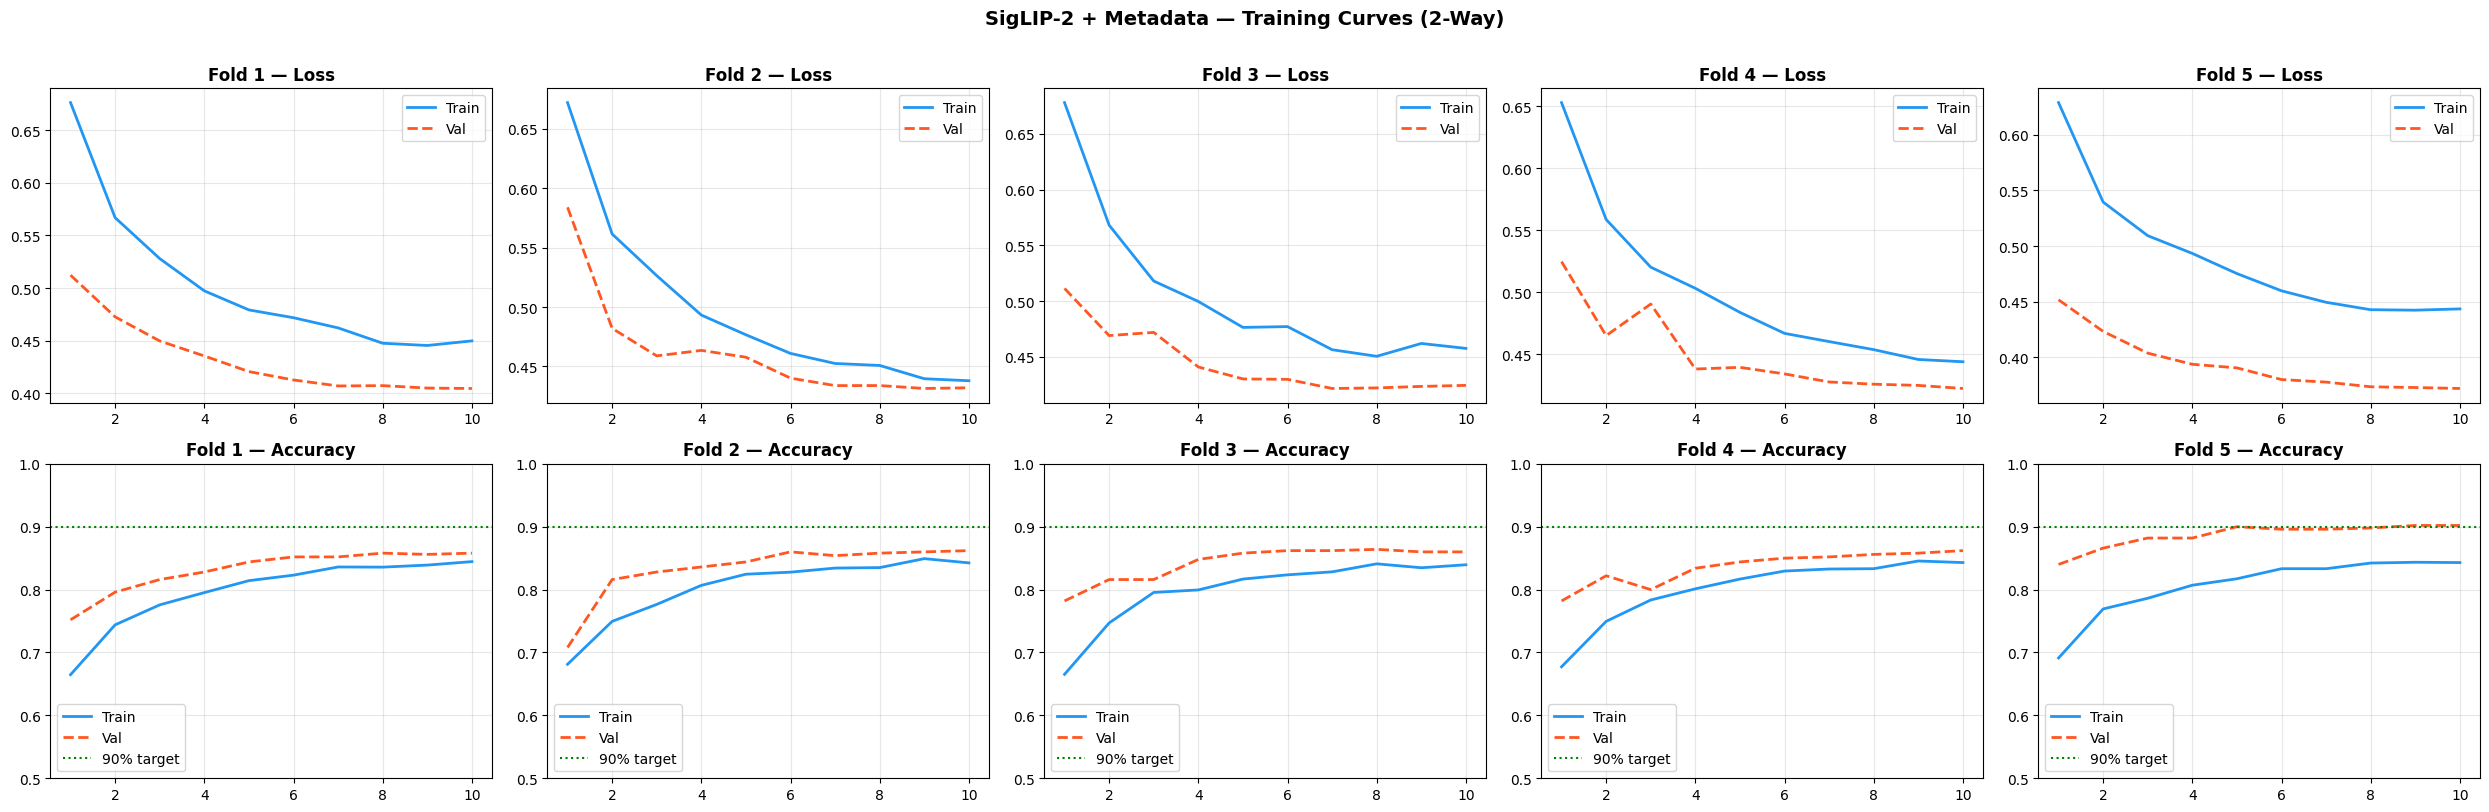

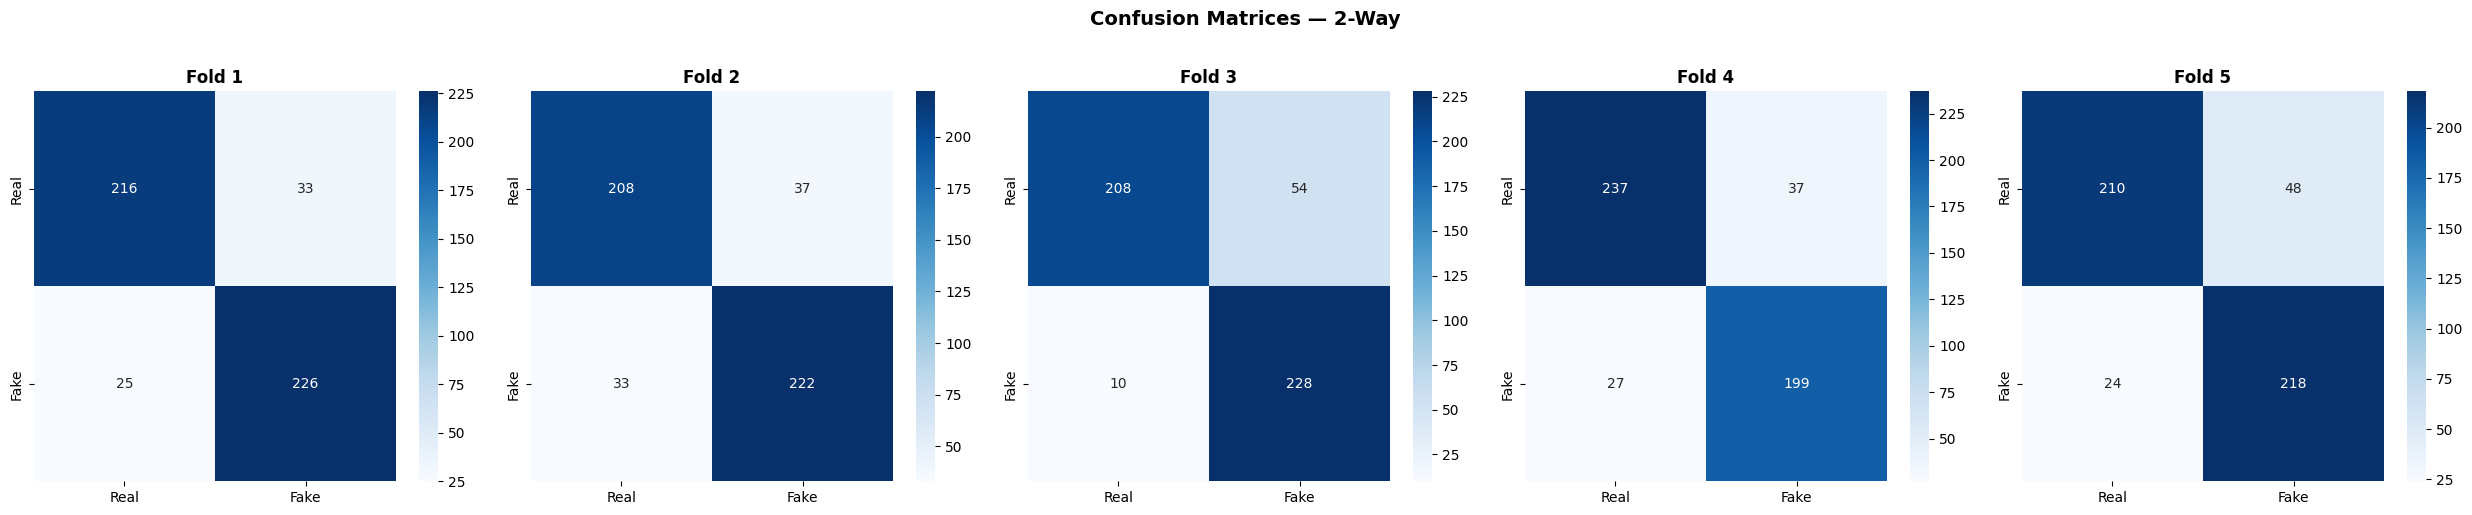


Visualizations saved to /kaggle/working/


In [13]:
# ── Cell 12: Generate Visualizations ──────────────────────────────────────────
plot_visualizations(all_history, all_cms)

In [14]:
# ── Cell 13: Final Summary ────────────────────────────────────────────────────
print("\n" + "=" * 70)
print("  FINAL SUMMARY")
print("=" * 70)
print(f"  Model       : SigLIP-2 SO400M-384")
print(f"  Dataset     : Fakeddit ({NUM_SAMPLES} balanced samples)")
print(f"  Task        : 2-way classification ONLY (Real vs Fake)")
print(f"  Metadata    : domain embedding + 13 numerical features")
print(f"  Note        : 3-way and 6-way classification CANCELLED")
print(f"  SWA         : {'enabled' if USE_SWA else 'disabled'}")
print()
print(f"  Performance (macro average):")
print(f"    Mean Test Accuracy  : {summary['mean_accuracy']:.4f}")
print(f"    Mean Test F1 Macro  : {summary['mean_f1']:.4f}")
print(f"    Mean Test Precision : {summary['mean_precision']:.4f}")
print(f"    Mean Test Recall    : {summary['mean_recall']:.4f}")
print(f"    Mean Overfit Gap    : {summary['mean_ovf_gap']:+.4f}")
print()
acc_ok = summary["mean_accuracy"] >= 0.90
gap_ok = abs(summary["mean_ovf_gap"]) < 0.05
acc_label = "MET" if acc_ok else ("NOT MET (gap %.4f)" % (0.90 - summary["mean_accuracy"]))
gap_label = "OK"  if gap_ok else "EXCEEDED"
print(f"  Target >= 90% Acc : {acc_label}")
print(f"  Overfit Gap < 5%  : {gap_label}")
print()
print(f"  Files saved to {OUTPUT_DIR}/:")
print(f"    siglip_meta_results.csv")
print(f"    training_curves.png")
print(f"    confusion_matrices.png")
print("\n" + "=" * 70)
print("  Training complete!")
print("=" * 70)



  FINAL SUMMARY
  Model       : SigLIP-2 SO400M-384
  Dataset     : Fakeddit (5000 balanced samples)
  Task        : 2-way classification ONLY (Real vs Fake)
  Metadata    : domain embedding + 13 numerical features
  Note        : 3-way and 6-way classification CANCELLED
  SWA         : enabled

  Performance (macro average):
    Mean Test Accuracy  : 0.8688
    Mean Test F1 Macro  : 0.8686
    Mean Test Precision : 0.8710
    Mean Test Recall    : 0.8699
    Mean Overfit Gap    : -0.0272

  Target >= 90% Acc : NOT MET (gap 0.0312)
  Overfit Gap < 5%  : OK

  Files saved to /kaggle/working/:
    siglip_meta_results.csv
    training_curves.png
    confusion_matrices.png

  Training complete!
